```{index} single: Pyomo; kernel library
```
```{index} single: quadratic optimization
```
```{index} single: application; support vector machines
```
```{index} single: application; binary classification
```
```{index} single: application; counterfeit banknotes
```
```{index} single: solver; HiGHS
```
```{index} single: solver; MOSEK
```
```{index} single: solver; Ipopt
```
# 5.4 Support vector machines for binary classification

Support Vector Machines (SVM) are a type of supervised machine learning model. Similar to other machine learning techniques based on regression, training an SVM classifier uses examples with known outcomes, and involves optimizing some measure of performance. The resulting classifier can then be applied to classify data with unknown outcomes.

In this notebook, we will demonstrate the process of training an SVM for binary classification using linear and quadratic optimization models. Our implementation will initially focus on linear support vector machines which separate the feature space by means of a hyperplane. We will explore both primal and dual formulations. Then, using kernels, the dual formulation is extended to binary classification in higher-order and nonlinear feature spaces. Several different formulations of the optimization problem are given in Pyomo and applied to a banknote classification application.

## Preamble: Install Pyomo and a solver

This cell selects and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and ipopt, then sets SOLVER to use the ipopt solver. If run elsewhere, it assumes Pyomo and the MOSEK solver have been previously installed and sets SOLVER to use the MOSEK solver via the Pyomo SolverFactory. It then verifies that SOLVER is available. For linear problems, the solver HiGHS is imported and used.

See [Solvers used in this book](../appendix/installing-pyomo-and-solvers.ipynb) for installation, licensing and the differences between solver interfaces.


In [1]:
import sys, os

if 'google.colab' in sys.modules:
    %pip install idaes-pse --pre >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null
    !idaes get-extensions --to ./bin 
    os.environ['PATH'] += ':bin'
    solver_NLO = "ipopt"
else:
    solver_NLO = "mosek"

import pyomo.environ as pyo 

solver_LO = "appsi_highs"
SOLVER_LO = pyo.SolverFactory(solver_LO)
SOLVER_NLO = pyo.SolverFactory(solver_NLO)

assert SOLVER_LO.available(), f"Solver {solver_LO} is not available."
assert SOLVER_NLO.available(), f"Solver {solver_NLO} is not available."
from pyomo.opt import assert_optimal_termination

# Small dual coefficients and polynomial kernels need accurate solutions.
if solver_NLO == "mosek":
    for option in ["intpnt_qo_tol_pfeas", "intpnt_qo_tol_dfeas", "intpnt_qo_tol_rel_gap"]:
        SOLVER_NLO.options["dparam." + option] = 1e-12
elif solver_NLO == "ipopt":
    SOLVER_NLO.options["tol"] = 1e-10
    SOLVER_NLO.options["acceptable_tol"] = 1e-10
    SOLVER_NLO.options["bound_relax_factor"] = 0


## Binary classification

Binary classifiers are functions designed to answer questions such as "does this medical test indicate disease?", "will this specific customer enjoy that specific movie?", "does this photo include a car?", or "is this banknote genuine or counterfeit?" These questions are answered based on the values of "features" that may include physical measurements or other types of data collected from a representative data set with known outcomes.

In this notebook we consider a binary classifier that might be installed in a vending machine to detect banknotes. The goal of the device is to accurately identify and accept genuine banknotes while rejecting counterfeit ones. The classifier's performance can be assessed using definitions in the following table, where "positive" refers to an instance of a genuine banknote.

| | Predicted Positive  | Predicted Negative | 
| :-- | :--: | :--: |
| Actual Positive | True Positive (TP) | False Negative (FN) |
| Actual Negative | False Positive (FP) | True Negative (TN) |

A vending machine user would be frustrated if a genuine banknote is incorrectly rejected as a false negative. **Sensitivity** is defined as the number of true positives (TP) divided by the total number of actual positives (TP + FN). A user of the vending machine would prefer high sensitivity because that means genuine banknotes are likely to be accepted.

The vending machine owner/operator, on the other hand, wants to avoid accepting counterfeit banknotes and would therefore prefer a low number of false positives (FP). **Precision** is the number of true positives (TP) divided by the total number of predicted positives (TP + FP). The owner/operator would prefer high precision because that means almost all the accepted notes are genuine.

To achieve high sensitivity, a classifier can follow the "innocent until proven guilty" standard, rejecting banknotes only when certain they are counterfeit. To achieve high precision, a classifier can adopt the "guilty unless proven innocent" standard, rejecting banknotes unless absolutely certain they are genuine. 

The challenge in developing binary classifiers is to balance these conflicting objectives and to optimize performance from both perspectives at the same time.

## The data set 

The following data set contains measurements from a collection of known genuine and known counterfeit banknote specimens. The data is taken from https://archive.ics.uci.edu/ml/datasets/banknote+authentication and includes four continuous statistical measures obtained from the wavelet transform of banknote images named "variance", "skewness", "curtosis", and "entropy", and a binary variable named "class" which is 0 if genuine and 1 if counterfeit.

### Read data

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(
    "https://raw.githubusercontent.com/mobook/MO-book/main/datasets/data_banknote_authentication.txt",
    header=None,
)
df.columns = ["variance", "skewness", "curtosis", "entropy", "class"]
df.name = "Banknotes"
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Using built-in `pandas` functionalities, we can get a quick overview of the data set.

In [3]:
df.describe()

,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


### Select features and training sets

We divide the data set into a **training set** for training the classifier, and a **testing set** for evaluating the performance of the trained classifier. In addition, we select a two dimensional subset of the features so that the results can be plotted for better exposition. Since our definition of a positive outcome corresponds to detecting a genuine banknote, the "class" feature is scaled to have values of 1 for genuine banknotes and -1 for counterfeit banknotes. 

In [4]:
# create training and test sets, random_state=0 for reproducibility
df_train, df_test = train_test_split(df, test_size=0.2, random_state=0)

# select training features
features = ["variance", "skewness"]

# separate into features and outputs
X_train = df_train[features]
y_train = 1 - 2 * df_train["class"]

# separate into features and outputs
X_test = df_test[features]
y_test = 1 - 2 * df_test["class"]

The function `scatter_labeled_data` below produces a 2D scatter plot of labeled data. The function assigns default labels and colors, and otherwise passes along other keyword arguments.

In [5]:
def scatter_labeled_data(X, y, labels=["+1", "-1"], colors=["g", "r"], **kwargs):
    # Prepend keyword arguments for all scatter plots
    kw = {"x": 0, "y": 1, "kind": "scatter", "alpha": 0.4}
    kw.update(kwargs)

    # Ignore warnings from matplotlib scatter plot
    import warnings

    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        kw["ax"] = X[y > 0].plot(**kw, c=colors[0], label=labels[0])
        X[y < 0].plot(**kw, c=colors[1], label=labels[1])

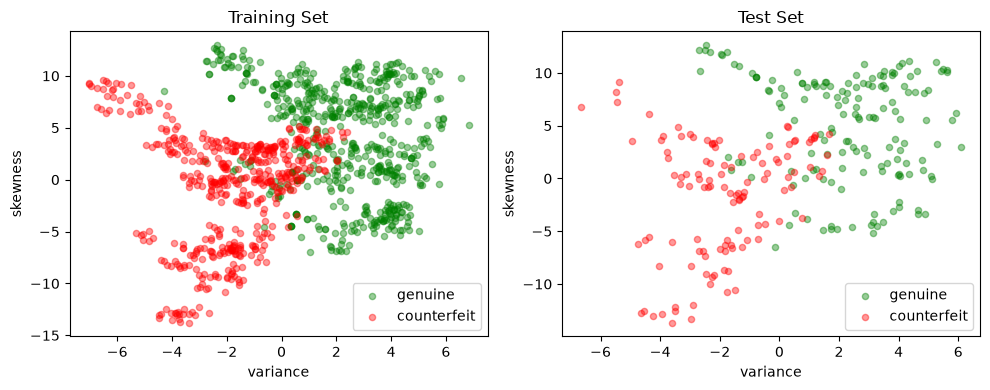

In [6]:
# plot training and test sets in two axes
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
scatter_labeled_data(
    X_train,
    y_train,
    labels=["genuine", "counterfeit"],
    ax=ax[0],
    title="Training Set",
)
scatter_labeled_data(
    X_test,
    y_test,
    labels=["genuine", "counterfeit"],
    ax=ax[1],
    title="Test Set",
)
plt.tight_layout()
plt.show()

## Support vector machines (SVM)

### Linear SVM classifier

A linear support vector machine (SVM) is a binary classification method that employs a linear equation to determine class assignment. The basic  formula is expressed as:

$$y^{pred} = \text{sgn}\ ( w^\top x + b)$$

where $x$ is a point $x\in\mathbb{R}^p$ in "feature" space. Here $w\in \mathbb{R}^p$ represents a set of coefficients, $w^\top x$ is the dot product, and $b$ is a scalar coefficient. The hyperplane defined by $w$ and $b$ separates the feature space into two classes. Points on one side of the hyperplane have a positive outcome (+1); while points on the other side have a negative outcome (-1).

The following cell presents a simple Python implementation of a linear SVM. An instance of `LinearSVM` is defined with a coefficient vector $w$ and a scalar $b$. In this implementation, all data and parameters are provided as Pandas Series or DataFrame objects, and the Pandas `.dot()` function is used to compute the dot product.
We use $\operatorname{sgn}(0)=+1$, assigning a point exactly on the decision boundary to the positive class.


In [7]:
def classify(scores):
    """Assign an exact zero score to the positive class (+1)."""
    scores = np.asarray(scores, dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError("Classifier scores must be finite.")
    return np.where(scores >= 0, 1, -1)


# Linear Support Vector Machine (SVM) class
class LinearSVM:
    # Initialize the Linear SVM with weights w and bias b
    def __init__(self, w, b):
        self.w = pd.Series(w)
        self.b = float(b)

    # Call method to compute the decision function using the input data X
    def __call__(self, X):
        return pd.Series(classify(X.dot(self.w) + self.b), index=X.index)

    # String representation method for the Linear SVM class
    def __repr__(self):
        return f"LinearSvm(w = {self.w.to_dict()}, b = {self.b})"

A visual inspection of the banknote training set shows the two dimensional feature set can be approximately split along a vertical axis where "variance" is zero. Most of the positive outcomes are on the right of the axis, most of the negative outcomes on the left. Since $w$ is a vector normal to this surface, we choose 

$$
\begin{align}
    w & = \begin{bmatrix} w_{variance} \\ w_{skewness} \end{bmatrix} = \begin{bmatrix} 1 \\ 0 \end{bmatrix},
    \qquad b = 0
\end{align}
$$

The code cell below evaluates the accuracy of the linear SVM by calculating the **accuracy score**, which is the fraction of samples that were predicted accurately.

In [8]:
# Visual estimate of w and b for a linear classifier
w = pd.Series({"variance": 1, "skewness": 0})
b = 0

# create an instance of LinearSVM
svm = LinearSVM(w, b)
print(svm)

# predictions for the test set
y_pred = svm(X_test)

# fraction of correct predictions
accuracy = sum(y_pred == y_test) / len(y_test)
print(f"Accuracy = {100 * accuracy: 0.1f}%")

LinearSvm(w = {'variance': 1, 'skewness': 0}, b = 0.0)
Accuracy =  82.9%


In [9]:
def scatter_comparison(X, y, y_pred):
    xmin, ymin = X.min()
    xmax, ymax = X.max()
    xlim = [xmin - 0.05 * (xmax - xmin), xmax + 0.05 * (xmax - xmin)]
    ylim = [ymin - 0.05 * (ymax - ymin), ymax + 0.05 * (ymax - ymin)]

    # Plot training and test sets
    labels = ["genuine", "counterfeit"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    scatter_labeled_data(
        X, y, labels, ["g", "r"], ax=ax[0], xlim=xlim, ylim=ylim, title="Actual"
    )
    scatter_labeled_data(
        X,
        y_pred,
        labels,
        ["c", "m"],
        ax=ax[1],
        xlim=xlim,
        ylim=ylim,
        title="Prediction",
    )
    plt.tight_layout()
    plt.show()

    # Plot actual positives and actual negatives
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    scatter_labeled_data(
        X[y > 0],
        y_pred[y > 0],
        ["true positive", "false negative"],
        ["c", "m"],
        xlim=xlim,
        ylim=ylim,
        ax=ax[0],
        title="Actual Positives",
    )
    scatter_labeled_data(
        X[y < 0],
        y_pred[y < 0],
        ["false positive", "true negative"],
        ["c", "m"],
        xlim=xlim,
        ylim=ylim,
        ax=ax[1],
        title="Actual Negatives",
    )
    plt.tight_layout()
    plt.show()

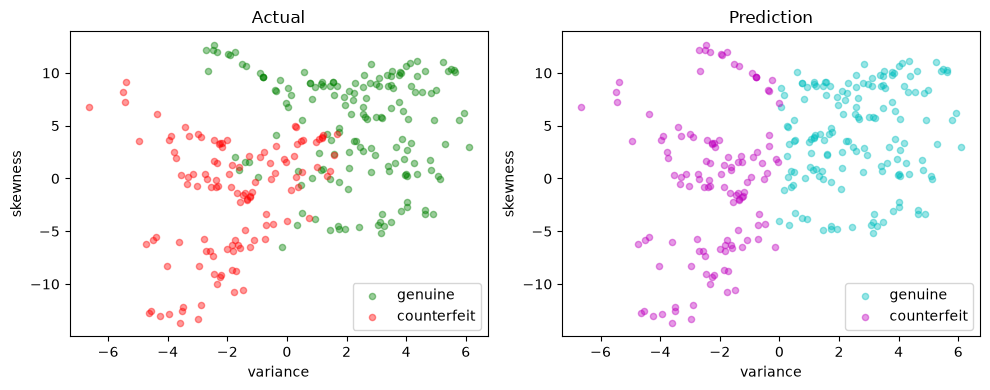

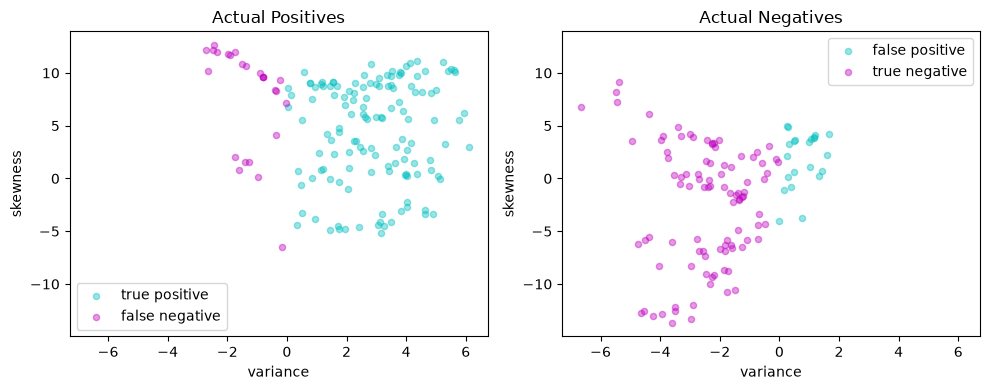

In [10]:
scatter_comparison(X_test, y_test, y_pred)

### Performance metrics

The accuracy score alone is not always a reliable metric for evaluating the performance of binary classifiers. For instance, when one outcome is significantly more frequent than the other, a classifier that always predicts the more common outcome without regard to the feature vector can achieve a very high accuracy score while being completely wrong on the less common outcome. Moreover, in many applications, the consequences of a false positive can differ from those of a false negative. For these reasons, we seek a more comprehensive set of metrics to compare binary classifiers. A [detailed discussion on this topic](https://bmcgenomics.biomedcentral.com/articles/10.1186/s12864-019-6413-7) recommends the [Matthews correlation coefficient (MCC)](https://towardsdatascience.com/the-best-classification-metric-youve-never-heard-of-the-matthews-correlation-coefficient-3bf50a2f3e9a) as a reliable performance measure for binary classifiers.

The code below demonstrates an example of a function that evaluates the performance of a binary classifier and returns the Matthews correlation coefficient as its output. The function `validate` calculates and displays the sensitivity, precision, and Matthews correlation coefficient (MCC) for a binary classifier based on its true labels (`y_true`) and predicted labels (`y_pred`).
All observations are counted, including decision-boundary ties. If a denominator is zero, the implementation reports zero for the corresponding MCC, sensitivity or precision by convention.


In [11]:
def validate(y_true, y_pred, verbose=True):
    # Align labelled observations before counting; arrays retain positional order.
    if isinstance(y_true, pd.Series) and isinstance(y_pred, pd.Series):
        if not y_true.index.is_unique or not y_pred.index.is_unique:
            raise ValueError("Observation labels must be unique.")
        if (len(y_true) != len(y_pred)
                or not y_true.index.isin(y_pred.index).all()):
            raise ValueError("True and predicted labels must identify the same observations.")
        y_pred = y_pred.reindex(y_true.index)
    # Count every observation, including an exact decision-boundary tie.
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if y_true.ndim != 1 or y_pred.shape != y_true.shape or y_true.size == 0:
        raise ValueError("Supply equally sized, nonempty one-dimensional arrays.")
    if not np.isin(y_true, [-1, 1]).all():
        raise ValueError("True labels must be -1 or +1.")
    y_pred = classify(y_pred)
    true_positives = int(np.count_nonzero((y_true > 0) & (y_pred > 0)))
    false_negatives = int(np.count_nonzero((y_true > 0) & (y_pred < 0)))
    false_positives = int(np.count_nonzero((y_true < 0) & (y_pred > 0)))
    true_negatives = int(np.count_nonzero((y_true < 0) & (y_pred < 0)))
    total = y_true.size

    # Calculate the Matthews correlation coefficient (MCC)
    mcc_numerator = (true_positives * true_negatives) - (
        false_positives * false_negatives
    )
    mcc_denominator = np.sqrt(
        (true_positives + false_positives)
        * (true_positives + false_negatives)
        * (true_negatives + false_positives)
        * (true_negatives + false_negatives)
    )
    mcc = mcc_numerator / mcc_denominator if mcc_denominator else 0.0

    if verbose:
        print(f"Matthews correlation coefficient (MCC) = {mcc:0.3f}")

        # report sensitivity and precision, and accuracy
        sensitivity = true_positives / (true_positives + false_negatives) if true_positives + false_negatives else 0.0
        precision = true_positives / (true_positives + false_positives) if true_positives + false_positives else 0.0
        accuracy = (true_positives + true_negatives) / total

        print(f"Sensitivity = {100 * sensitivity: 0.1f}%")
        print(f"Precision = {100 * precision: 0.1f}%")
        print(f"Accuracy = {100 * accuracy: 0.1f}%")

        # Display the binary confusion matrix
        confusion_matrix = pd.DataFrame(
            [
                [true_positives, false_negatives],
                [false_positives, true_negatives],
            ],
            index=["Actual Positive", "Actual Negative"],
            columns=["Predicted Positive", "Predicted Negative"],
        )
        display(confusion_matrix)

    return mcc


LinearSvm(w = {'variance': 1, 'skewness': 0}, b = 0.0) 

Matthews correlation coefficient (MCC) = 0.652
Sensitivity =  84.1%
Precision =  85.7%
Accuracy =  82.9%


,Predicted Positive,Predicted Negative
Actual Positive,132,25
Actual Negative,22,96


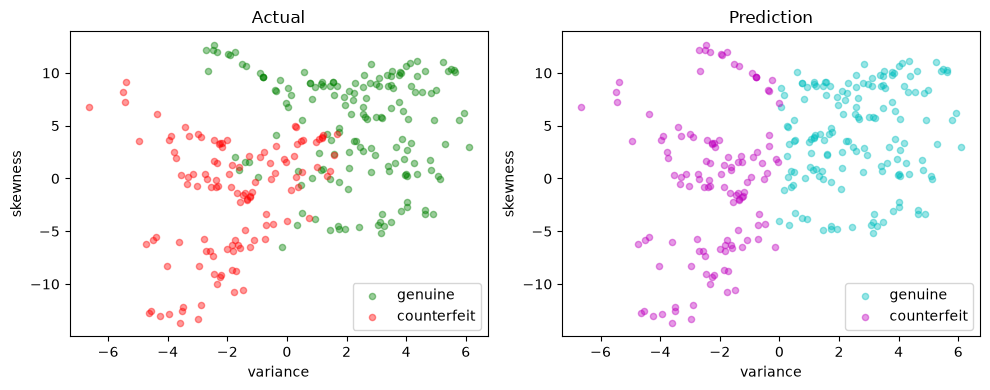

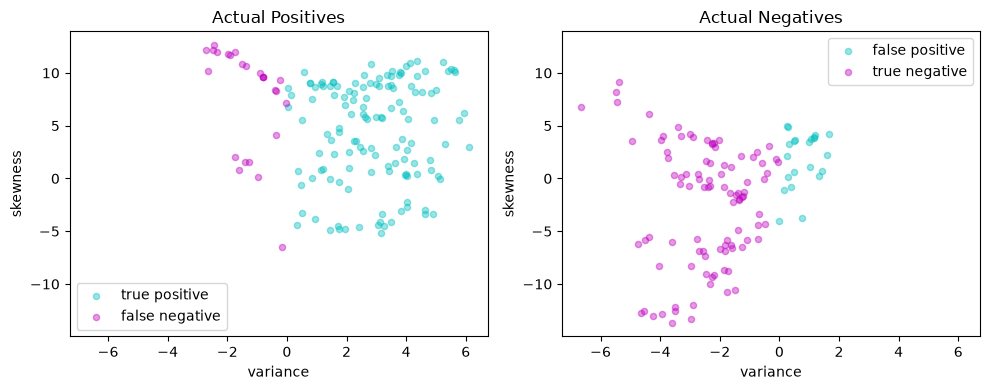

In [12]:
def test(svm, X_test, y_test):
    y_pred = svm(X_test)
    print(svm, "\n")
    validate(y_test, y_pred)
    scatter_comparison(X_test, y_test, y_pred)


# train and test
naive_svm = LinearSVM({"variance": 1, "skewness": 0}, 0.0)
test(naive_svm, X_test, y_test)

## Linear optimization model

A training or validation set consists of $n$ observations $(x_i, y_i)$ where $y_i = \pm 1$ and $x_i\in\mathbb{R}^p$ for $i=1, \dots, n$. The training task is to find coefficients $w\in\mathbb{R}^p$ and $b\in\mathbb{R}$ by fitting the training set; the held-out test set is then used to evaluate sensitivity and precision. All points $(x_i, y_i)$ for $i\in\{1,\dots,n\}$ are successfully classified if
 
$$
\begin{align}
    y_i (w^\top x_i + b) & > 0 & \forall i\in\{1,2,\dots,n\}.
\end{align}
$$

As written, this condition imposes no scale for $w$ or $b$ (that is, if the condition is satisfied for any pair $(w, b)$, then it is also satisfied for $(\gamma w, \gamma b)$ where $\gamma > 0$). To remove the ambiguity, a modified condition for correctly classified points is given by

$$
\begin{align*}
y_i (w^\top x_i + b) & \geq 1 & \forall i\in\{1,2,\dots,n\}
\end{align*}
$$

which defines a **hard-margin** classifier. The size of the margin is determined by the scale of $w$ and $b$. 

In practice, it is not always possible to find $w$ and $b$ that perfectly separate all data. The condition for a hard-margin classifier is therefore relaxed by introducing non-negative decision variables $z_i \geq 0$ where

$$
\begin{align*}
y_i (w^\top x_i + b) & \geq 1 - z_i & \forall i\in\{1,2,\dots,n\}
\end{align*}
$$

The variables $z_i$ bound the margin violations. With a positive penalty on each slack, their values at an optimum are

$$
\begin{align*}
    z_i & = \max(0,  1 -  y_i (w^\top x_i + b)) & \forall i\in\{1,2,\dots,n\}
\end{align*}
$$

which is the **hinge-loss** function. A correctly classified point inside the margin can have positive hinge loss; this is not its geometric distance to the hyperplane. The training problem is formulated as minimizing the hinge-loss function over all the data samples:

$$
\begin{align*}
    \min_{w, b} \frac{1}{n}\sum_{i=1}^n \left(1 - y_i(w^\top x_i + b)\right)^+ .
\end{align*}
$$

Practice has shown that minimizing this term alone produces classifiers with large entries for $w$ which perform poorly on new data samples. For that reason, **regularization** adds a term to penalize the magnitude of $w$. In most formulations a norm $\|w\|$ is used for regularization, commonly a sum of squares such as $\|w\|_2^2$. Another choice is $\|w\|_1$ which, similar to Lasso regression, may result in sparse weighting vector $w$ indicating the elements of the feature vector that can be neglected for classification purposes. These considerations result in the objective function

$$
    \min_{w, b}\left[ \lambda \|w\|_1 + \frac{1}{n}\sum_{i=1}^n \left(1 - y_i(w^\top x_i + b)\right)^+ \right]
$$

The needed weights are a solution to the following linear optimization problem:

$$
\begin{align*}
\min\quad  & \lambda \|w\|_1 + \frac{1}{n} \sum_{i=1}^n z_i \\
\text{s.t.} \quad &  z_i \geq 1 - y_i(w^\top x_i + b) & \forall i\in\{1,\dots,n\} \\
& z_i\geq 0 & \forall i\in\{1,\dots,n\} \\
& w\in\mathbb{R}^p \\
& b\in\mathbb{R} \\
\end{align*}
$$

This is the primal optimization problem in decision variables $w\in\mathbb{R}^p$, $b\in\mathbb{R}$, and $z\in\mathbb{R}^n$, a total of $n + p + 1$ unknowns with $2n$ constraints. This can be recast as a linear optimization problem with the usual technique of setting $w = w^+ - w^-$ where $w^+$ and $w^-$ are non-negative. Then

$$
\begin{align*}
\min\quad  &\lambda \sum_{j=1}^p (w^+_j + w^-_j) + \frac{1}{n}  \sum_{i=1}^n z_i \\
\text{s.t.} \quad &  z_i \geq 1 - y_i((w^+ - w^-)^\top x_i + b) & \forall i\in\{1,\dots,n\} \\
& z_i \geq 0 & \forall i\in\{1,\dots,n\} \\
& w^+_j, w^-_j \geq 0 & \forall j\in\{1,\dots,p\} \\
& b\in\mathbb{R} \\
\end{align*}
$$

### Pyomo implementation

The factory creates and returns a Pyomo `ConcreteModel`. The following code solves it and constructs a `LinearSVM` classifier that can be applied to other feature data.

LinearSvm(w = {'variance': 0.2481706514167256, 'skewness': 0.050359568144785205}, b = -0.004552873871603941) 

Matthews correlation coefficient (MCC) = 0.755
Sensitivity =  93.0%
Precision =  86.9%
Accuracy =  88.0%


,Predicted Positive,Predicted Negative
Actual Positive,146,11
Actual Negative,22,96


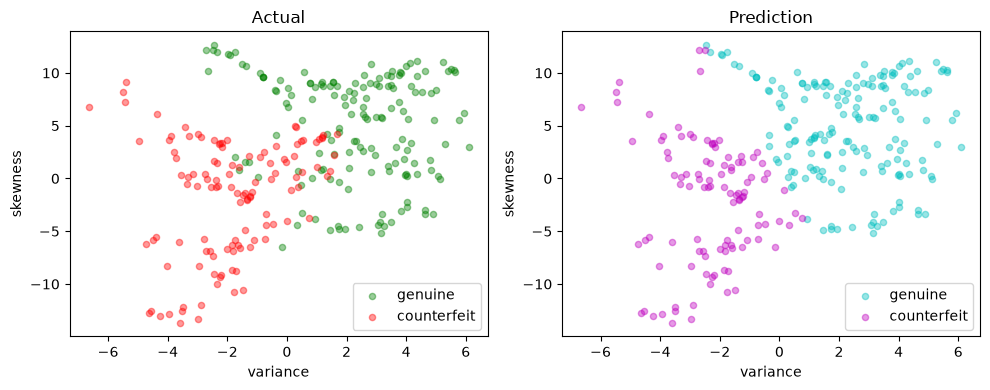

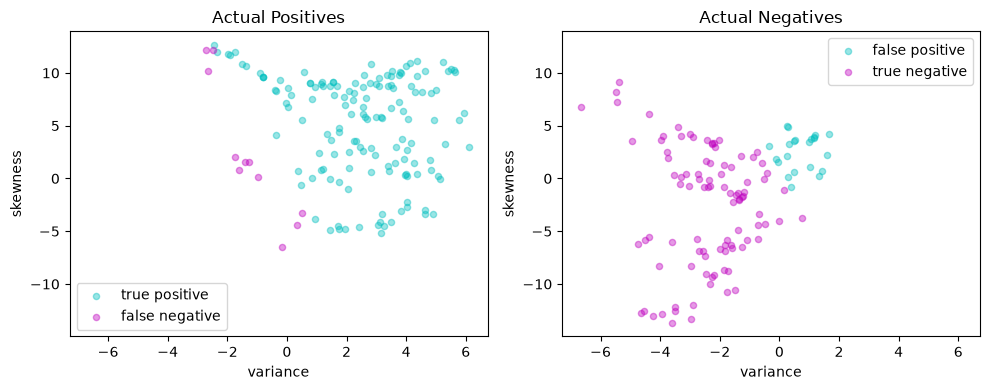

In [13]:
def svm_linear(X, y, lambd=1):
    m = pyo.ConcreteModel("Linear SVM")

    # Use dataframe columns and index to index variables and constraints
    m.P = pyo.Set(initialize=X.columns)
    m.N = pyo.Set(initialize=X.index)

    # Decision variables
    m.wp = pyo.Var(m.P, domain=pyo.NonNegativeReals)
    m.wn = pyo.Var(m.P, domain=pyo.NonNegativeReals)
    m.b = pyo.Var()
    m.z = pyo.Var(m.N, domain=pyo.NonNegativeReals)

    @m.Expression(m.P)
    def w(m, p):
        return m.wp[p] - m.wn[p]

    @m.Objective(sense=pyo.minimize)
    def lasso(m):
        return sum(m.z[i] for i in m.N) / len(m.N) + lambd * sum(
            m.wp[p] + m.wn[p] for p in m.P
        )

    @m.Constraint(m.N)
    def hingeloss(m, i):
        return m.z[i] >= 1 - y[i] * (sum(m.w[p] * X.loc[i, p] for p in m.P) + m.b)

    return m


m = svm_linear(X_train, y_train)
results = SOLVER_LO.solve(m)
assert_optimal_termination(results)
w = pd.Series([m.w[p]() for p in m.P], index=m.P)
b = m.b()
linear_svm = LinearSVM(w, b)
test(linear_svm, X_test, y_test)

## Quadratic optimization model

### Primal form

The standard formulation of a linear support vector machine uses training sets with $p$-element feature vectors $x_i\in\mathbb{R}^p$ along with classification labels for those vectors, $y_i = \pm 1$. A classifier is defined by two parameters: a weight vector $w\in\mathbb{R}^p$ and a bias term $b\in\mathbb{R}$

$$
\begin{align*}
y^{pred} & = \text{sgn}(w^\top x + b)
\end{align*}
$$

If a separating hyperplane exists, then we choose $w$ and $b$ so that a hard-margin classifier exists for the training set $(x_i, y_i)$ where

$$
\begin{align*}
y_i \left( w^\top x_i + b \right) & \geq 1 & \forall i\in\{1,2,\dots,n\}
\end{align*}
$$

This can always be done if a separating hyperplane exists. But if a separating hyperplane does not exist, we introduce non-negative slack variables $z_i$ to relax the constraints and settle for a soft-margin classifier 

$$
\begin{align*}
y_i \left( w^\top x_i + b \right) & \geq 1 - z_i& \forall i\in\{1,2,\dots,n\}
\end{align*}
$$ 

The training objective balances weight regularization against hinge loss, with $z_i=\max\{0,1-y_i(w^\top x_i+b)\}$ at an optimum for $c>0$. This leads to the optimization problem

$$
\begin{align*}
\min\quad  & \frac{1}{2} \|w \|_2^2 + \frac{c}{n} \sum_{i=1}^n z_i \\
\text{s.t.} \quad &  z_i \geq 1 - y_i(w^\top x_i + b) & \forall i\in\{1,\dots,n\} \\
& z_i\geq 0 & \forall i\in\{1,\dots,n\} \\
& w\in\mathbb{R}^p \\
& b\in\mathbb{R}
\end{align*}
$$

where $\frac{1}{2} \|w\|_2^2$ is included to regularize the solution for $w$. The intercept $b$ is unpenalized; stationarity with respect to $b$ gives $\sum_i\alpha_i y_i=0$ in the dual. Larger values of $c$ put more weight on reducing hinge loss relative to regularization, without guaranteeing fewer classification errors on new data. 

The following cell creates a support vector machine (SVM) model using a quadratic optimization starting from data.

LinearSvm(w = {'variance': 0.37012561116677223, 'skewness': 0.11556091295503755}, b = -0.120573871316664) 

Matthews correlation coefficient (MCC) = 0.754
Sensitivity =  92.4%
Precision =  87.3%
Accuracy =  88.0%


,Predicted Positive,Predicted Negative
Actual Positive,145,12
Actual Negative,21,97


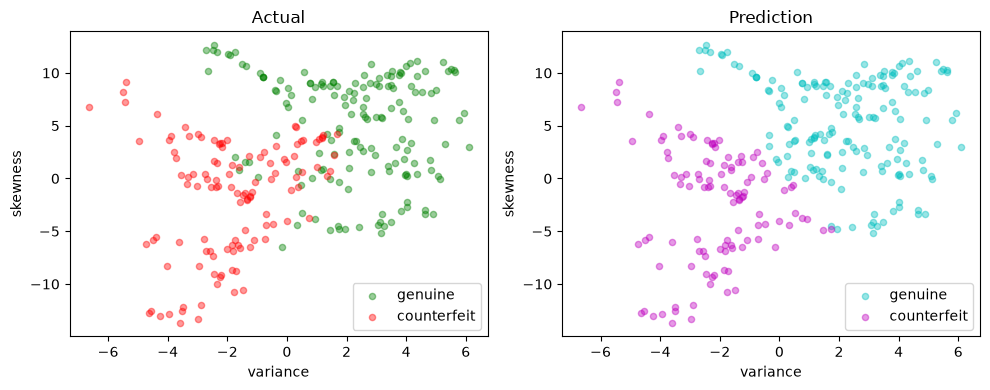

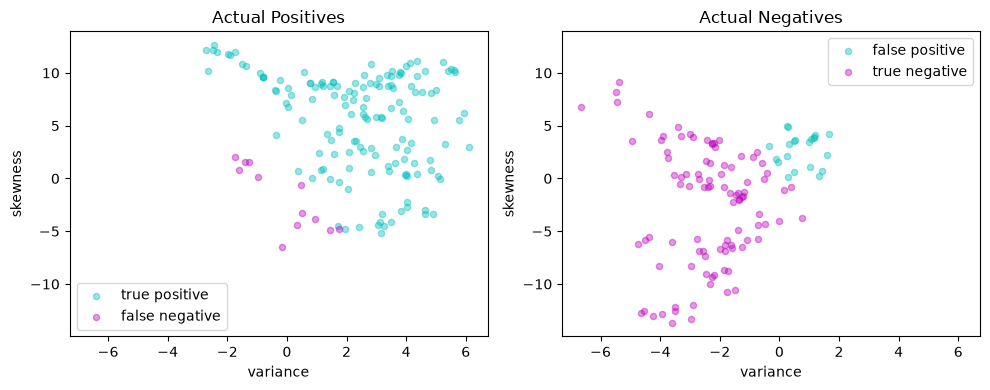

In [14]:
def svm_quadratic(X, y, c=1):
    m = pyo.ConcreteModel("SVM quadratic with L2 regularization")

    # Use dataframe columns and index to index variables and constraints
    m.P = pyo.Set(initialize=X.columns)
    m.N = pyo.Set(initialize=X.index)

    # Decision variables
    m.w = pyo.Var(m.P)
    m.b = pyo.Var()
    m.z = pyo.Var(m.N, domain=pyo.NonNegativeReals)

    @m.Objective(sense=pyo.minimize)
    def qp(m):
        return sum(m.w[i] ** 2 for i in m.P) / 2 + (c / len(m.N)) * sum(
            m.z[i] for i in m.N
        )

    @m.Constraint(m.N)
    def hingeloss(m, i):
        return m.z[i] >= 1 - y[i] * (sum(m.w[p] * X.loc[i, p] for p in m.P) + m.b)

    return m


m = svm_quadratic(X_train, y_train)
results = SOLVER_NLO.solve(m)
assert_optimal_termination(results)
w = pd.Series([m.w[p]() for p in m.P], index=m.P)
b = m.b()
quadratic_svm = LinearSVM(w, b)
test(quadratic_svm, X_test, y_test)

(dual-formulation)=
### Dual formulation

The dual formulation for the SVM provides insight into how a linear SVM works and is essential for extending SVM to nonlinear classification. The dual formulation begins by creating a differentiable Lagrangian with dual variables $\alpha_i \geq 0$ and $\beta_i \geq 0$ for $i\in\{1,\dots,n\}$. The task is to find saddle points of

$$
\begin{align*}
\mathcal{L} & = \frac{1}{2} \|w\|_2^2 + \frac{c}{n}\sum_{i=1}^n z_i + \sum_{i=1}^n \alpha_i \left(1 - z_i - y_i (w^\top x_i + b) \right) + \sum_{i=1}^n \beta_i (-z_i) \\
\end{align*}
$$

Taking derivatives with respect to the primal variables

$$
\begin{align*}
\frac{\partial \mathcal{L}}{\partial z_i} & = \frac{c}{n} - \alpha_i - \beta_i = 0 \implies 0 \leq \alpha_i \leq \frac{c}{n}\\
\frac{\partial \mathcal{L}}{\partial w} & = w  - \sum_{i=1}^n \alpha_i y_i x_i = 0 \implies  w = \sum_{i=1}^n \alpha_i y_i x_i \\
\frac{\partial \mathcal{L}}{\partial b} & = - \sum_{i=1}^n \alpha_i y_i = 0 \implies \sum_{i=1}^n \alpha_i y_i = 0
\end{align*}
$$

This can be arranged in the form of a standard quadratic optimization problem in $n$ variables $\alpha_i$ for $i\in\{1,\dots,n\}$.

$$
\begin{align*}
\min \quad  & \frac{1}{2} \sum_{i=1}^n\sum_{j=1}^n \alpha_i \alpha_j y_i y_j ( x_i^\top x_j ) -  \sum_{i=1}^n \alpha_i \\
\text{s.t.}\quad & \sum_{i=1}^n \alpha_i y_i = 0  \\
& \alpha_i \in \left[0, \frac{c}{n}\right] & i\in\{1,\dots,n\} \\
\end{align*}
$$

The symmetric $n \times n$ **Gram matrix** is defined as

$$
    G = \begin{bmatrix} 
        (y_1 x_1^\top)(y_1 x_1) & \dots & (y_1 x_1^\top)(y_n x_n) \\ 
        \vdots & \ddots & \vdots \\ 
        (y_n x_n^\top)(y_1 x_1) & \dots & (y_n x_n^\top)(y_n x_n)
    \end{bmatrix}
$$

where each entry is the dot product of two vectors $(y_i x_i), (y_j x_j) \in \mathbb{R}^{p}$. 

Compared to the primal, the dual formulation appears to have reduced the number of decision variables from $n + p + 1$ to $n$. But this has come with the penalty of introducing a dense matrix with $n^2$ coefficients and potential processing time of order $n^3$. For large training sets where $n\sim 10^4-10^6$ or even larger, this becomes a prohibitively expensive calculation. In addition, the Gram matrix will be rank deficient for cases $p< n$. 

We can eliminate the need to compute and store the full Gram matrix $G$ by introducing the $n \times p$ matrix $F$
 
$$
    F = \begin{bmatrix} y_1 x_1^\top \\ y_2 x_2^\top \\ \vdots \\ y_n x_n^\top \end{bmatrix}
$$

Then $G = FF^\top$ which brings the $p$ primal variables $w = F^\top\alpha$ back into the computational problem. The optimization problem becomes

$$
\begin{align*}
\min \quad & \frac{1}{2} w^\top w -  1^\top\alpha \\
\text{s.t.}\quad & y^\top\alpha = 0 \\
& w = F^\top\alpha \\
& 0 \leq \alpha_i \leq \frac{c}{n} & i\in\{1,\dots,n\}\\
& \alpha\in\mathbb{R}^n\\
& w\in\mathbb{R}^p.
\end{align*}
$$

The solution for the bias term $b$ is obtained by considering the complementarity conditions on the dual variables. The slack variables $z_i$ are zero if $\beta_i > 0$ which is equivalent to $\alpha_i < \frac{c}{n}$. If $\alpha_i > 0$, complementarity gives $1-y_i(w^\top x_i+b)-z_i=0$. Putting these facts together gives a formula for $b$

$$
\begin{align}
b & = y_i - w^\top x_i & \forall i\in\{1,2,\ldots,n\}\quad \text{s.t.}\quad 0 < \alpha_i < \frac{c}{n}\\
\end{align}
$$

For numerical recovery of $b$, use coefficients strictly inside $[0,C]$, where $C=c/n$, with a tolerance relative to $C$. If none are interior, the KKT conditions give an interval instead. Writing $r_i=y_i-w^\top x_i$, positive labels with $\alpha_i=0$ and negative labels with $\alpha_i=C$ give lower bounds $b\geq r_i$. The opposite label/bound combinations give upper bounds $b\leq r_i$. Any value between the largest lower bound and smallest upper bound is valid. The helper below chooses the midpoint of a finite interval, or the point closest to zero for a one-sided interval.

This model is implemented below.

LinearSvm(w = {'variance': 0.37012561114064274, 'skewness': 0.1155609129639896}, b = -0.12057387100168204) 

Matthews correlation coefficient (MCC) = 0.754
Sensitivity =  92.4%
Precision =  87.3%
Accuracy =  88.0%


,Predicted Positive,Predicted Negative
Actual Positive,145,12
Actual Negative,21,97


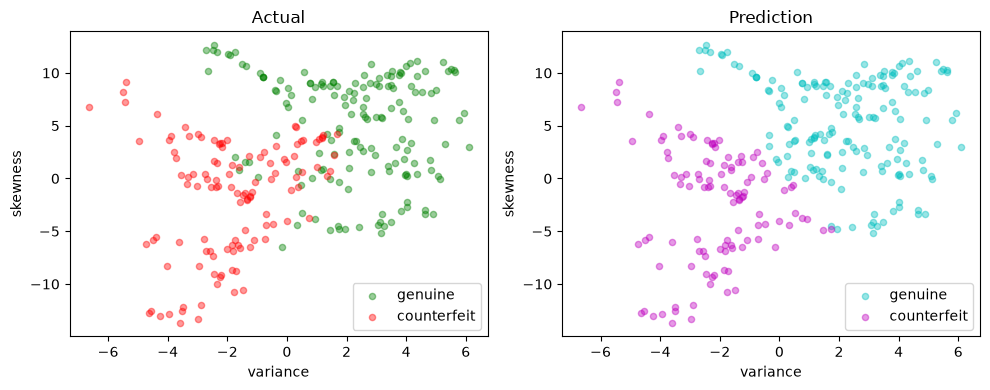

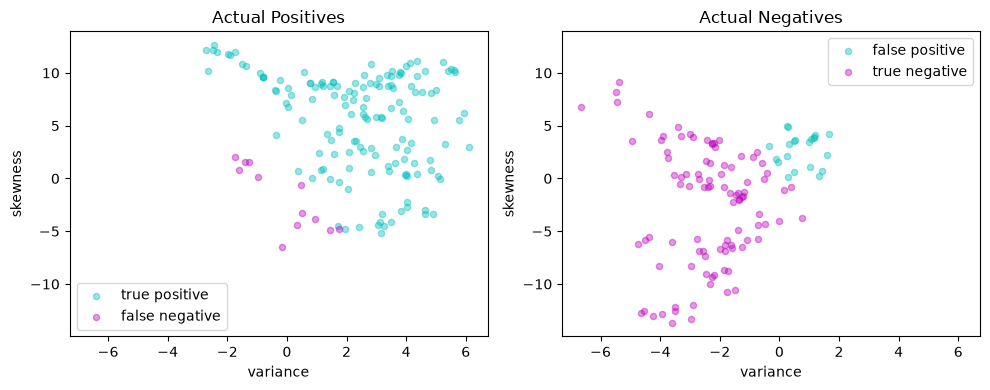

In [15]:
def svm_bias(y, scores, a, C, tol=1e-4):
    """Recover the unpenalized intercept from KKT conditions.

    scores excludes the intercept; tol is relative to C=c/n.
    """
    C = pyo.value(C)
    eps = tol * C
    candidates = y - scores
    interior = (a > eps) & (a < C - eps)
    if interior.any():
        return float(candidates[interior].mean())

    at_lower, at_upper = a <= eps, a >= C - eps
    lower = max(candidates[(at_lower & (y == 1)) | (at_upper & (y == -1))], default=-np.inf)
    upper = min(candidates[(at_lower & (y == -1)) | (at_upper & (y == 1))], default=np.inf)
    if lower > upper + 1e-6:
        raise ValueError("Inconsistent KKT bounds; check solver accuracy.")
    if np.isfinite(lower) and np.isfinite(upper):
        return float((lower + upper) / 2)
    return float(np.clip(0.0, lower, upper))


def svm_dual(X, y, c=1):
    m = pyo.ConcreteModel("Linear SVM Dual")

    # Use dataframe columns and index to index variables and constraints
    m.P = pyo.Set(initialize=X.columns)
    m.N = pyo.Set(initialize=X.index)

    # Model parameters
    F = X.mul(y, axis=0)
    m.C = pyo.Param(initialize=c / len(m.N))

    # Decision variables
    m.w = pyo.Var(m.P)
    m.a = pyo.Var(m.N, bounds=(0, m.C))

    @m.Objective(sense=pyo.minimize)
    def dualqp(m):
        return sum(m.w[i] ** 2 for i in m.P) / 2 - sum(m.a[i] for i in m.N)

    @m.Constraint()
    def bias(m):
        return sum(y.loc[i] * m.a[i] for i in m.N) == 0

    @m.Constraint(m.P)
    def projection(m, p):
        return m.w[p] == sum(F.loc[i, p] * m.a[i] for i in m.N)

    return m


m = svm_dual(X_train, y_train)
results = SOLVER_NLO.solve(m)
# Extract the optimal values of w and b
assert_optimal_termination(results)
w = pd.Series([m.w[p]() for p in m.P], index=m.P)
a = pd.Series([m.a[i]() for i in m.N], index=m.N)
b = svm_bias(y_train, X_train.dot(w), a, m.C)
dual_svm = LinearSVM(w, b)
test(dual_svm, X_test, y_test)

## Kernelized SVM

### Nonlinear feature spaces

A linear SVM uses a linear decision boundary. A soft-margin model can accommodate data that are not perfectly linearly separable. Nonlinear features can provide a more flexible decision boundary. 

Consider a binary classifier given by

$$y^{pred} = \text{sgn} \left( w^\top \phi(x) + b \right)$$

where $\phi(x)$ is a function mapping $x$ into a higher dimensional "feature space". That is, $\phi : \mathbb{R}^{p} \rightarrow \mathbb{R}^d$ where $d \geq p $. The additional dimensions may include features such as powers of the terms in $x$, or products of those terms, or other types of nonlinear transformations. As before, we wish to find a choice for $w\in\mathbb{R}^d$ such that the soft-margin constraints hold:

$$
\begin{align}
y_i \left( w^\top \phi(x_i) + b \right) & \geq 1 - z_i  & i\in\{1,2,\ldots,n\}
\end{align}
$$

Using the machinery as before, we set up the Lagrangian

$$
\begin{align*}
\mathcal{L} & = \frac{1}{2} \|w\|_2^2 + \frac{c}{n}\sum_{i=1}^n z_i + \sum_{i=1}^n \alpha_i \left( 1 - z_i - y_i \left( w^\top \phi(x_i) + b \right)\right) + \sum_{i=1}^n \beta_i (-z_i) \\
\end{align*}
$$

then take derivatives to find

$$
\begin{align*}
    \frac{\partial \mathcal{L}}{\partial z_i} & = \frac{c}{n} - \alpha_i - \beta_i = 0 \implies 0 \leq \alpha_i \leq \frac{c}{n}\\
    \frac{\partial \mathcal{L}}{\partial w} & = w  - \sum_{i=1}^n \alpha_i y_i \phi(x_i) = 0 \implies  w = \sum_{i=1}^n \alpha_i y_i \phi(x_i) \\
\frac{\partial \mathcal{L}}{\partial b} & = - \sum_{i=1}^n \alpha_i y_i = 0 \implies \sum_{i=1}^n \alpha_i y_i = 0
\end{align*}
$$

This is similar to the case of a linear SVM, but now the vector of weights $w\in\mathbb{R}^d$ belongs to a high-dimensional feature space with nonlinear features. Working through the algebra, we are once again left with a quadratic optimization problem in $n$ variables $\alpha_i$ for $i\in\{1,\dots,n\}$.

$$
\begin{align*}
\min_{\alpha_i}\quad  & \frac{1}{2} \sum_{i=1}^n\sum_{j=1}^n \alpha_i \alpha_j y_i y_j  \phi(x_i)^\top \phi(x_j) -  \sum_{i=1}^n \alpha_i \\
\text{s.t.}\quad & \alpha_i \in \left[0, \frac{c}{n}\right] & i\in\{1,\dots,n\} \\
& \sum_{i=1}^n \alpha_i y_i = 0 \\
\end{align*}
$$

where the resulting classifier is given by 

$$y^{pred} = \text{sgn} \left( \sum_{i=1}^n \alpha_i y_i \phi(x_i)^\top \phi(x) + b \right)$$

### The kernel trick

This is an interesting situation where the separating hyperplane is embedded in a high dimensional space of nonlinear features determined by the mapping $\phi(x)$, but all we need for computation are the inner products  $\phi(x_i)^\top\phi(x_j)$ to train the classifier, and the inner products $\phi(x_i)^\top\phi(x)$ to use the classifier. If we had a function $K(x, z)$ that returned the value $\phi(x)^\top\phi(z)$ then we would never need to actually compute $\phi(x)$, $\phi(z)$ or their inner product.

Mercer's theorem turns the analysis on its head by specifying conditions under which a function $K(x, z)$ can be expressed as an inner product for some $\phi(x)$. If $K(x, z)$ is symmetric (i.e., $K(x, z) = K(z, x)$), and if the Gram matrix constructed for any collection of points $x_1, x_2, \ldots, x_n$ 

$$
\begin{bmatrix} 
    K(x_1, x_1) & \dots & K(x_1, x_n) \\ 
    \vdots & \ddots & \vdots \\ 
    K(x_n, x_1) & \dots & K(x_n, x_n) 
\end{bmatrix}
$$

is positive semi-definite, then there is some $\phi(x)$ for which $K(x, z)$ is an inner product. We call such functions kernels. The practical consequence is that we can train and implement nonlinear classifiers using kernels without ever needing to compute the higher dimensional features. This remarkable result is called the "kernel trick".

### Implementation

To take advantage of the kernel trick, we assume an appropriate kernel $K(x, z)$ has been identified, then replace all instances of $\phi(x_i)^\top \phi(x)$ with the kernel. The "kernelized" SVM is given by a solution to 

$$
\begin{align*}
\min_{\alpha_i}\quad & \frac{1}{2} \sum_{i=1}^n\sum_{j=1}^n \alpha_i \alpha_j y_i y_j K(x_i, x_j) -  \sum_{i=1}^n \alpha_i \\
\text{s.t.}\quad & \sum_{i=1}^n \alpha_i y_i = 0 \\
& \alpha_i \in \left[0, \frac{c}{n}\right] & i\in\{1,\dots,n\} \\
\end{align*}
$$

where

$$
\begin{align}
b & = y_i - \sum_{j=1}^n \alpha_j y_j K(x_j, x_i) & \forall i\in\{1,2,\ldots,n\}\quad \text{s.t.}\quad 0 < \alpha_i < \frac{c}{n}
\end{align}
$$

where the resulting classifier is given by 

$$y^{pred} = \text{sgn} \left( \sum_{i=1}^n \alpha_i y_i K(x_i, x) + b \right)$$

We define the $n\times n$ positive symmetric semi-definite Gram matrix

$$
G = \begin{bmatrix} 
    y_1 y_1 K(x_1, x_1) & \dots & y_1 y_n K(x_1, x_n) \\ 
    \vdots & \ddots & \vdots \\ 
    y_n y_1 K(x_n, x_1) & \dots & y_n y_n K(x_n, x_n) 
\end{bmatrix}
$$

We factor $G = F F^\top$ where $F$ has dimensions $n \times q$ and where $q$ is the rank of $G$. The factorization is not unique. As demonstrated in the Python code below, one suitable factorization is the spectral factorization $G = U\Lambda U^T$ where $\Lambda$ is a $q\times q$ diagonal matrix of non-zero eigenvalues, and $U$ is an $n\times q$ matrix with orthonormal columns such that $U^\top U = I_q$. Then

$$F = U\Lambda^{1/2}$$

Once this factorization is complete, the optimization problem for the kernelized SVM is the same as for the linear SVM in the dual formulation

$$
\begin{align*}
\min\quad & \frac{1}{2} \alpha^\top F F^\top \alpha -  1^\top \alpha \\
\text{s.t.}\quad & \sum_{i=1}^n \alpha_i y_i = 0 \\
& 0 \leq \alpha_i \leq \frac{c}{n} & \alpha\in\mathbb{R}^n \\
\end{align*}
$$

The result is a quadratic optimization model for the dual coefficients $\alpha$ and auxiliary variables $v$.

$$
\begin{align*}
\min\quad & \frac{1}{2} v^\top v - 1^\top \alpha\\
\text{s.t.}\quad & y^\top \alpha = 0 \\
& v = F^\top \alpha & v\in\mathbb{R}^{q} \\
& 0 \leq \alpha_i \leq \frac{c}{n} & \alpha\in\mathbb{R}^n \\
\end{align*}
$$

Summarizing, the essential difference between training the linear and kernelized SVM is the need to compute and factor the Gram matrix. The result will be a set of non-zero coefficients $\alpha_i > 0$ that define a set of support vectors $\mathcal{SV}$. The classifier is then given by

$$y^{pred} = \text{sgn} \left( \sum_{i\in\mathcal{SV}} \alpha_i y_i K(x_i, x) + b \right)$$

The implementation of the kernelized SVM is split into two parts. The first part is a class used to create instances of the classifier.


In [16]:
class KernelSVM:
    # Initialize the Kernel SVM with weights and bias
    def __init__(self, X, y, a, b, kernel):
        self.X = np.array(X)
        self.u = np.multiply(np.array(a), np.array(y))
        self.b = b
        self.kernel = kernel

    # Call method to compute the decision function using the input dataframe Z
    def __call__(self, Z):
        Z_ = Z.to_numpy()
        K = [
            [self.kernel(self.X[i, :], Z_[j, :]) for j in range(len(Z_))]
            for i in range(len(self.X))
        ]
        y_pred = classify((self.u @ K) + self.b)
        return pd.Series(y_pred, index=Z.index)

The second part of the implementation is a factory function containing the optimization model for training an SVM. Given training data and a kernel function, the factory returns an instance of a kernelized SVM. The default for the kernel function is a linear kernel. An additional optional argument is the scalar `tol`, which is the tolerance for the eigenvalue threshold. Small dual coefficients combined with polynomial kernels require accurate solves, so the preamble tightens the relevant solver tolerances. After solving, we check dual feasibility and the primal-dual objective gap. Predictions retain all computed coefficients; the threshold used to color support vectors is only for visualization.

In [17]:
def svm_kernel_model(X, y, c=1, tol=1e-8, kernel=lambda x, z: x @ z):
    # Convert to numpy arrays for speed improvement
    n, p = X.shape
    X_ = X.to_numpy()
    y_ = y.to_numpy()

    # Gram matrix
    G = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            G[j, i] = G[i, j] = y_[i] * y_[j] * kernel(X_[i, :], X_[j, :])

    # Factor the Gram matrix
    eigvals, eigvecs = np.linalg.eigh(G)
    idx = eigvals >= tol * max(eigvals)
    F = pd.DataFrame(eigvecs[:, idx] @ np.diag(np.sqrt(eigvals[idx])), index=X.index)

    # Build model
    m = pyo.ConcreteModel("SVM with kernel")
    m.G = G  # retain the Gram matrix for bias and optimality checks

    # Use dataframe columns and index to index variables and constraints
    m.Q = pyo.Set(initialize=F.columns)
    m.N = pyo.Set(initialize=F.index)

    # Model parameters
    m.C = pyo.Param(initialize=c / len(m.N))

    # Decision variables
    m.u = pyo.Var(m.Q)
    m.a = pyo.Var(m.N, bounds=(0, m.C))

    @m.Objective(sense=pyo.minimize)
    def kernelqp(m):
        return sum(m.u[i] ** 2 for i in m.Q) / 2 - sum(m.a[i] for i in m.N)

    @m.Constraint()
    def bias(m):
        return sum(y.loc[i] * m.a[i] for i in m.N) == 0

    @m.Constraint(m.Q)
    def projection(m, q):
        return m.u[q] == sum(F.loc[i, q] * m.a[i] for i in m.N)

    return m


def svm_kernel(X, y, c=1, tol=1e-8, kernel=lambda x, z: x @ z):
    # create an optimization model for SVM binary classifier using a kernel
    m = svm_kernel_model(X, y, c=c, tol=tol, kernel=kernel)

    # Solve with the interior point method
    results = SOLVER_NLO.solve(m)

    # Extract solution
    assert_optimal_termination(results)
    sol = pd.Series([m.a[i]() for i in m.N], index=m.N)

    # Recover the intercept and check the solution in the original kernel.
    scores = pd.Series(y.to_numpy() * (m.G @ sol.to_numpy()), index=X.index)
    b = svm_bias(y, scores, sol, m.C)
    C = pyo.value(m.C)
    assert sol.min() >= -1e-8 * C and sol.max() <= C * (1 + 1e-8)
    assert abs(sol.dot(y)) <= 1e-8 * C
    norm_squared = float(sol.to_numpy() @ m.G @ sol.to_numpy())
    primal = norm_squared / 2 + C * np.maximum(0, 1 - y * (scores + b)).sum()
    dual = sol.sum() - norm_squared / 2
    assert abs(primal - dual) <= 1e-7 * (1 + abs(primal))

    # Display the support vectors
    y_support = pd.Series(
        [1 if m.a[i]() > 1e-4 * m.C else -1 for i in m.N], index=X.index
    )
    scatter_labeled_data(
        X,
        y_support,
        colors=["b", "y"],
        labels=["Support Vector 1", "Support Vector 2"],
    )

    # Keep all coefficients so numerical thresholding cannot change predictions.
    return KernelSVM(X, y, sol, b, kernel)

### Linear kernel

For comparison with the previous cases, the first kernel we consider is a linear kernel

$$ K(x, z) = x^\top z $$

which should reproduce the results obtained earlier.


Matthews correlation coefficient (MCC) = 0.754
Sensitivity =  92.4%
Precision =  87.3%
Accuracy =  88.0%


,Predicted Positive,Predicted Negative
Actual Positive,145,12
Actual Negative,21,97


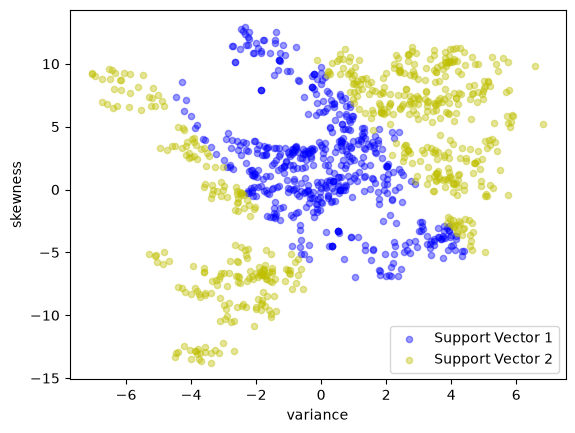

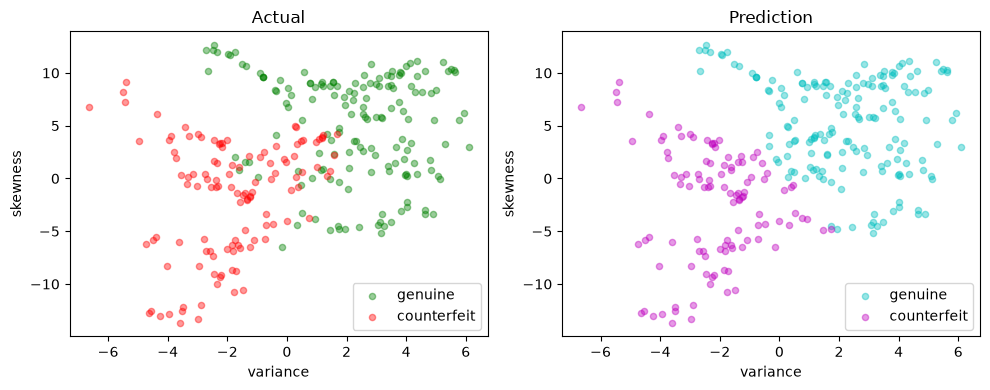

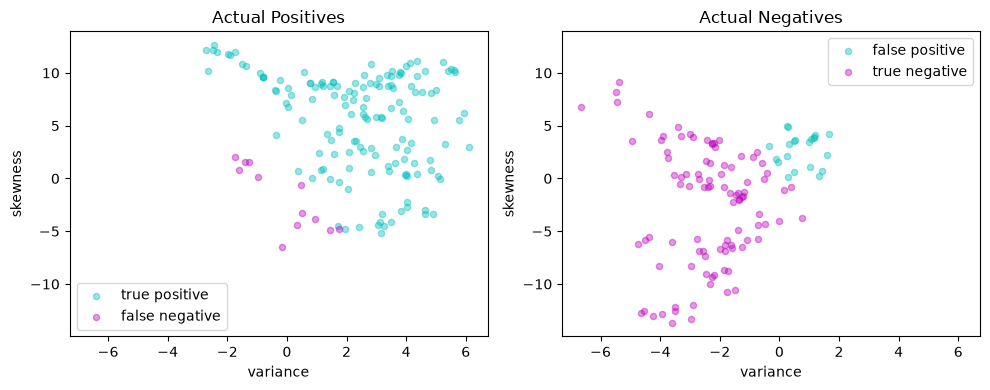

In [18]:
linear_kernel_svm = svm_kernel(X_train, y_train)
test(linear_kernel_svm, X_test, y_test)

### Polynomial kernels

A polynomial kernel of order $d$ has the form

$$K(x, z) = (1 + x^\top z)^d$$

The following cell demonstrates a quadratic kernel applied to the banknote data.



Matthews correlation coefficient (MCC) = 0.800
Sensitivity =  91.1%
Precision =  91.7%
Accuracy =  90.2%


,Predicted Positive,Predicted Negative
Actual Positive,143,14
Actual Negative,13,105


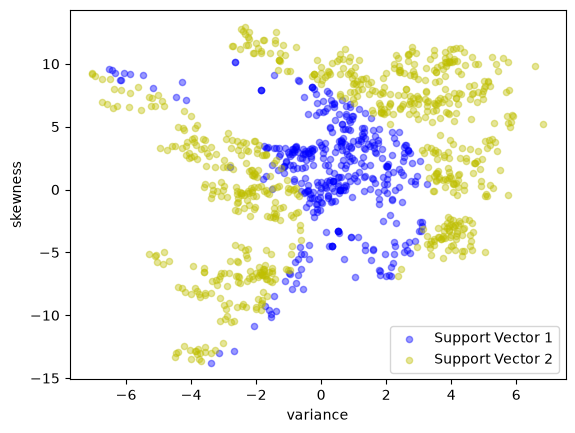

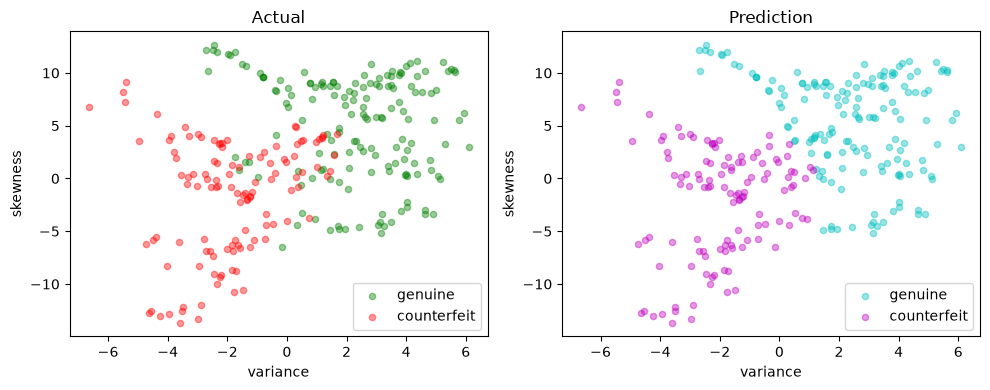

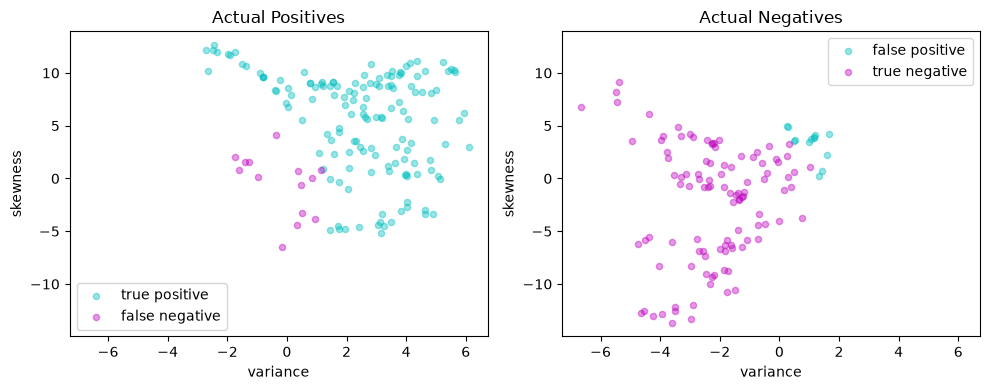

In [19]:
quadratic = lambda x, z: (1 + x @ z) ** 2
quadratic_kernel_svm = svm_kernel(X_train, y_train, kernel=quadratic)
test(quadratic_kernel_svm, X_test, y_test)


Matthews correlation coefficient (MCC) = 0.860
Sensitivity =  88.5%
Precision =  98.6%
Accuracy =  92.7%


,Predicted Positive,Predicted Negative
Actual Positive,139,18
Actual Negative,2,116


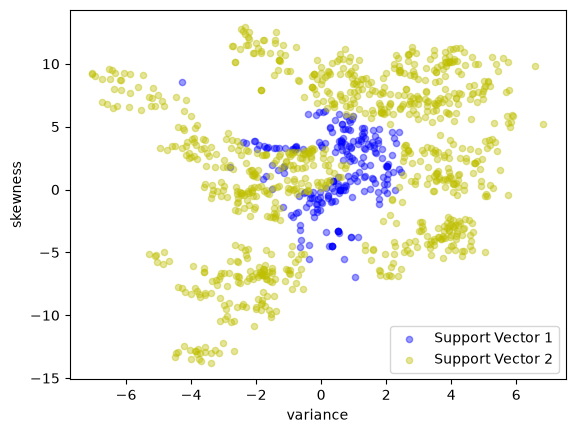

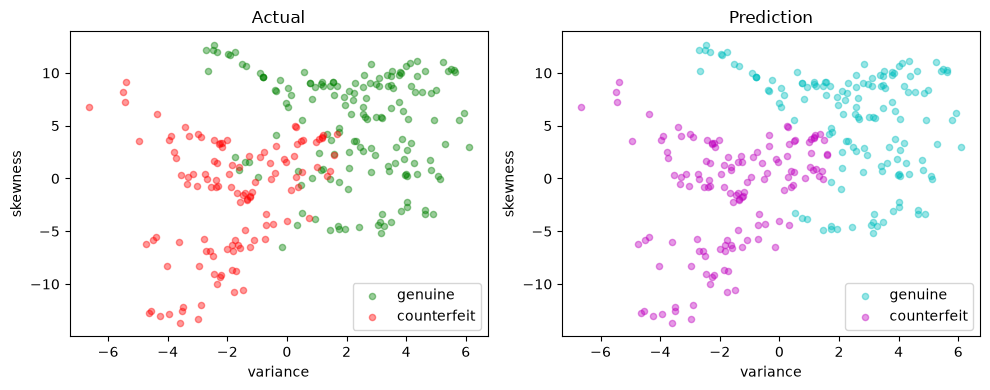

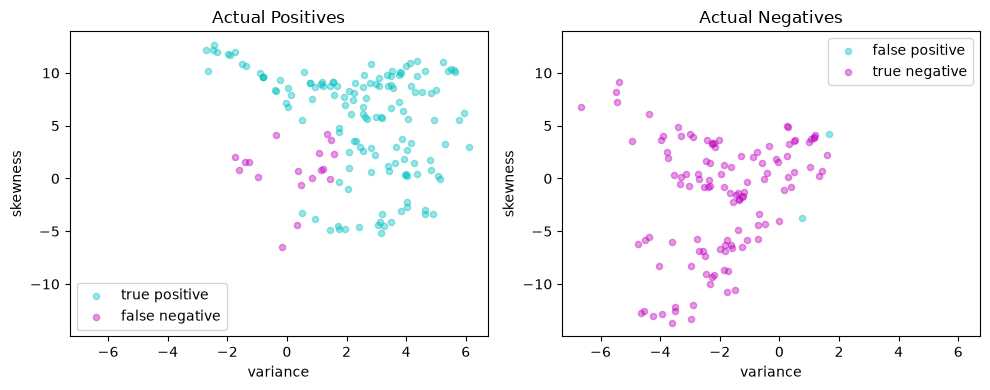

In [20]:
cubic = lambda x, z: (1 + x @ z) ** 3
cubic_kernel_svm = svm_kernel(X_train, y_train, kernel=cubic)
test(cubic_kernel_svm, X_test, y_test)